# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

from aitlas.datasets import AerialMaritimeDroneDataset 
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects witn bounding boxes

Total number of patches: 319


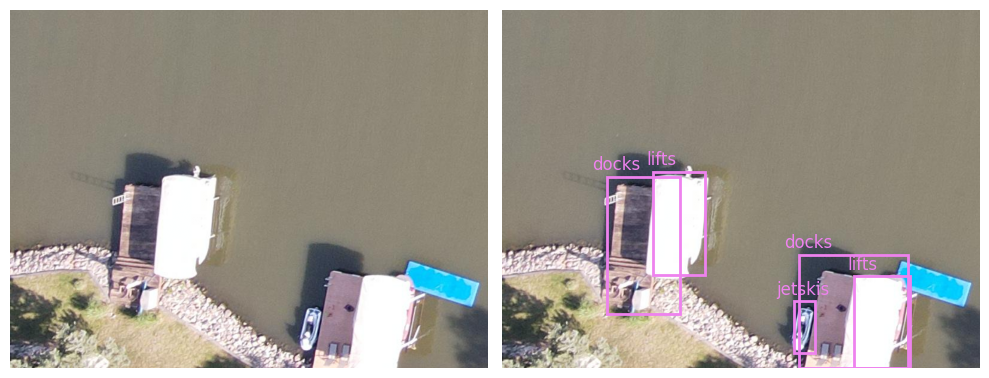

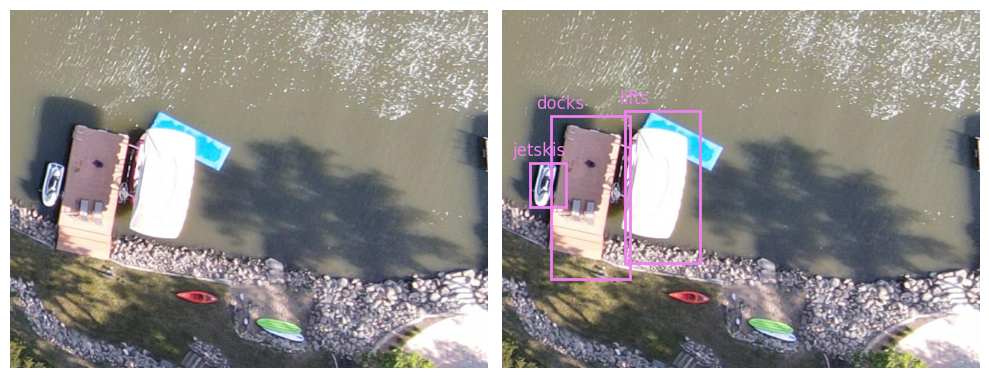

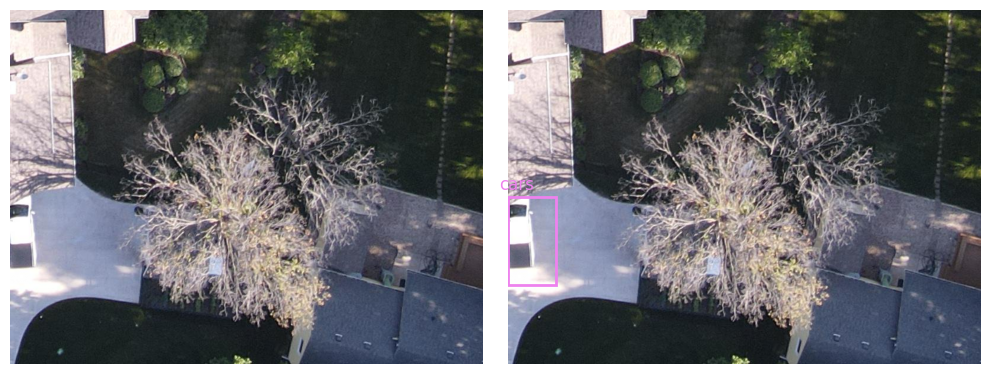

In [53]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/aerial_maritime_drone/images/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/aerial_maritime_drone/labels/",
}
dataset = AerialMaritimeDroneDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(2);
dataset.show_image(30);
dataset.show_image(80);

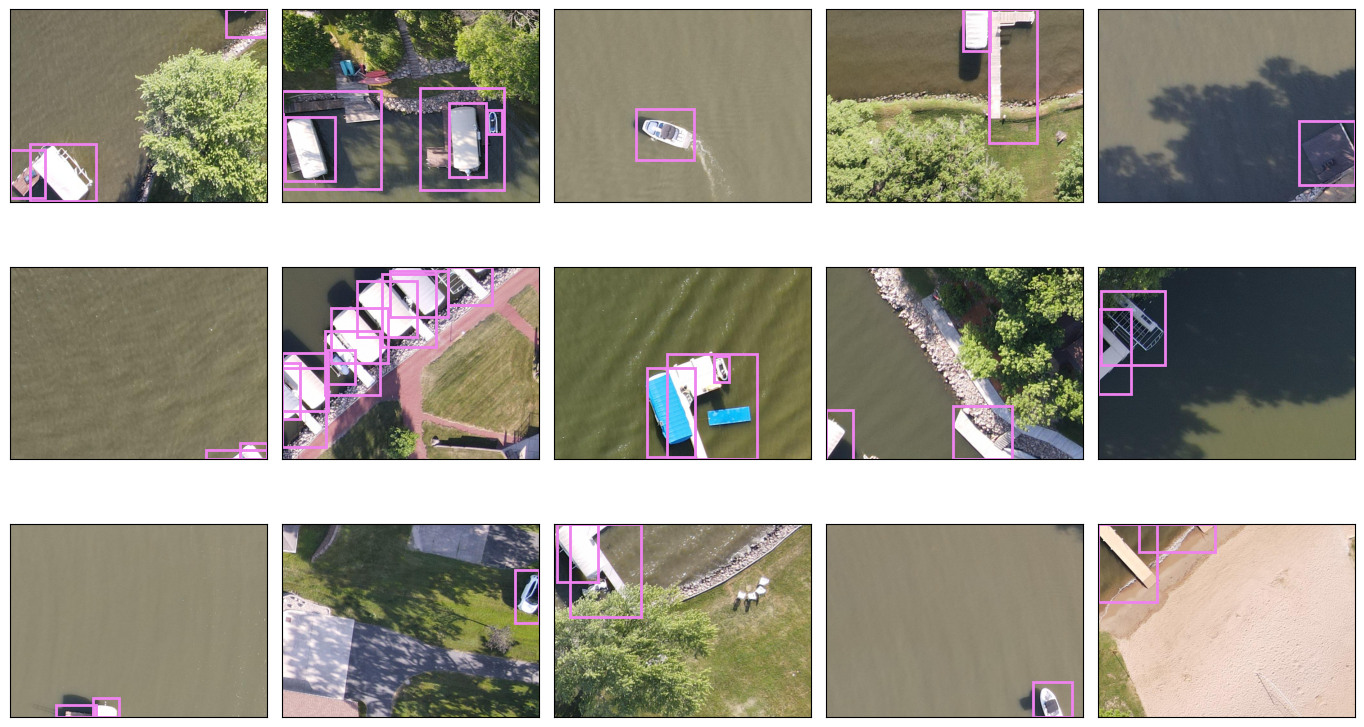

In [34]:
dataset.show_batch(15);

In [35]:
dataset.data_distribution_table()

,Label,Count
0,boats,39
1,cars,17
2,docks,407
3,jetskis,98
4,lifts,356


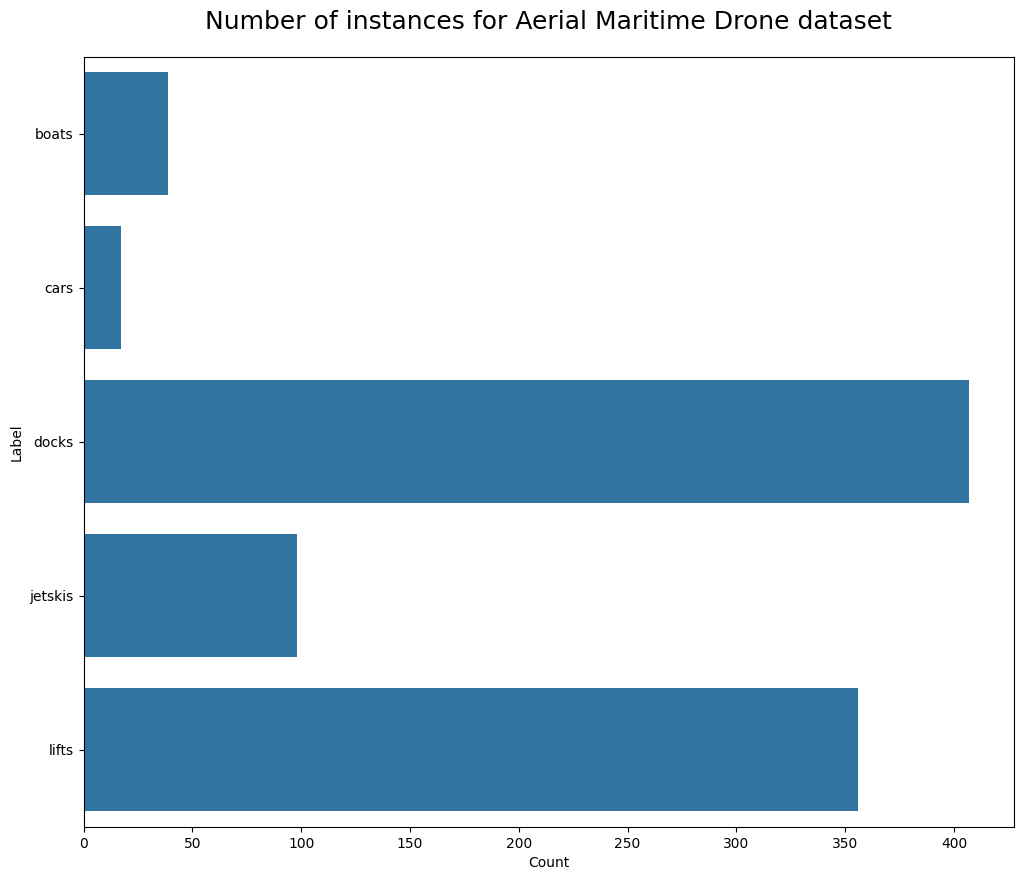

In [36]:
dataset.data_distribution_barchart();

## Load train data

In [57]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "/home/dragik/data/FAIR_EO/aerial_maritime_drone/train/images/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/aerial_maritime_drone/train/labels/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = AerialMaritimeDroneDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 230


## Create the model

In [58]:
epochs = 20
model_directory = "/home/dragik/data/FAIR_EO/aerial_maritime_drone/experiments/"
model_config = {
    "num_classes": 5,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [59]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-05 09:26:20,920 INFO Starting training.
training: 100%|██████████| 29/29 [00:10<00:00,  2.79it/s]
2025-05-05 09:26:31,353 INFO epoch: 1, time: 11, loss:  0.76891
testing on train set: 100%|██████████| 29/29 [00:05<00:00,  4.84it/s]
2025-05-05 09:26:39,260 INFO map:0.09374123811721802, map_50:0.18947206437587738, map_75:0.08299212902784348, map_small:0.0011244695633649826, map_medium:0.07696434110403061, map_large:0.1482931226491928, mar_1:0.08305010944604874, mar_10:0.12744227051734924, mar_100:0.12744227051734924, mar_small:0.008571428246796131, mar_medium:0.11521367728710175, mar_large:0.18858805298805237, map_per_class:tensor(0.), tensor(0.), tensor(0.0792), tensor(0.), tensor(0.3895), mar_100_per_class:tensor(0.), tensor(0.), tensor(0.1431), tensor(0.), tensor(0.4941), classes:tensor(0, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(2, dtype=torch.int32), tensor(3, dtype=torch.int32), tensor(4, dtype=torch.int32)
training: 100%|██████████| 29/29 [00:10<00:00,  2.7

## Evaluate the model

In [60]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "/home/dragik/data/FAIR_EO/aerial_maritime_drone/valid/images/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/aerial_maritime_drone/valid/labels/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = AerialMaritimeDroneDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/aerial_maritime_drone/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 61


2025-05-05 09:34:24,867 INFO Loading checkpoint /home/dragik/data/FAIR_EO/aerial_maritime_drone/experiments/checkpoint.pth.tar
2025-05-05 09:34:25,170 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/aerial_maritime_drone/experiments/checkpoint.pth.tar at epoch 21
testing on test set: 100%|██████████| 8/8 [00:02<00:00,  3.56it/s]


[{'map': 0.2387530505657196,
  'map_50': 0.42577096819877625,
  'map_75': 0.2546204924583435,
  'map_small': 0.0,
  'map_medium': 0.25623366236686707,
  'map_large': 0.2888753414154053,
  'mar_1': 0.23734848201274872,
  'mar_10': 0.293720543384552,
  'mar_100': 0.293720543384552,
  'mar_small': 0.0,
  'mar_medium': 0.32545894384384155,
  'mar_large': 0.32896101474761963,
  'map_per_class': [tensor(0.),
   tensor(0.1431),
   tensor(0.3069),
   tensor(0.3275),
   tensor(0.4163)],
  'mar_100_per_class': [tensor(0.),
   tensor(0.1833),
   tensor(0.3806),
   tensor(0.4455),
   tensor(0.4593)],
  'classes': [tensor(0, dtype=torch.int32),
   tensor(1, dtype=torch.int32),
   tensor(2, dtype=torch.int32),
   tensor(3, dtype=torch.int32),
   tensor(4, dtype=torch.int32)]}]

## Predictions

2025-05-05 09:34:53,748 INFO Loading checkpoint /home/dragik/data/FAIR_EO/aerial_maritime_drone/experiments/checkpoint.pth.tar
2025-05-05 09:34:54,049 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/aerial_maritime_drone/experiments/checkpoint.pth.tar at epoch 21


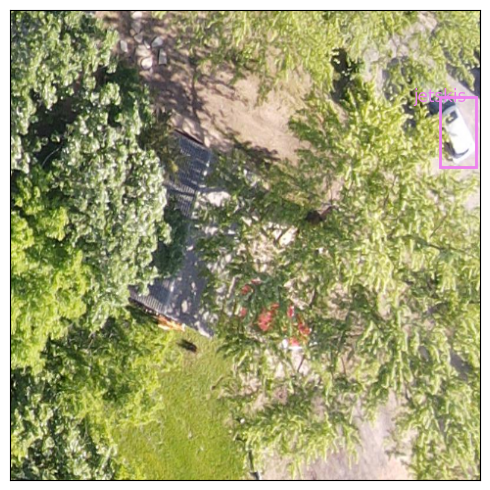

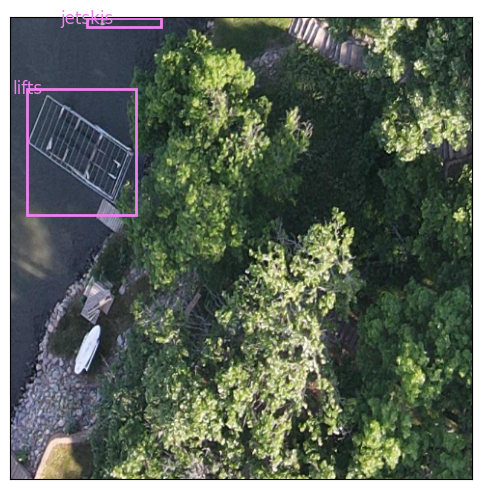

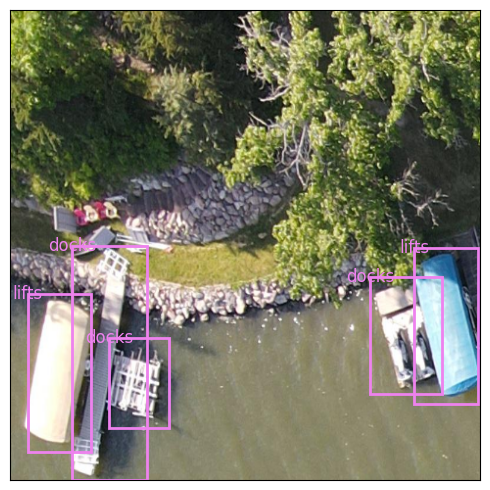

In [62]:
model_config = {
    "num_classes": 5,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/aerial_maritime_drone/experiments/checkpoint.pth.tar"
labels = ["boats", "cars", "docks","jetskis", "lifts"]
transform = Resize()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/aerial_maritime_drone/test/images/DJI_0262_JPG.rf.47ce7cf6d8e3e310ab9b2b5c15ebba72.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/aerial_maritime_drone/test/images/DJI_0262_JPG.rf.e495eab7bad50083023383cc09ce2cf6.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/aerial_maritime_drone/test/images/DJI_0312_JPG.rf.08f23849d327cc10139c06bae49506f4.jpg')
fig = model.detect_objects(image, labels, transform)